In [1]:
import gc, hashlib, itertools, json, math, pickle, random, shutil, sys, traceback
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from tqdm.auto import tqdm

sys.path.insert(0, "kev")
from models.kev_pointer import KevPointerModel


def make_one_hot(row):
    codes = row["option_codes"]
    if len(codes) != len(row["option_texts"]):
        raise ValueError(f"{row['qid']}: option_codes ({len(codes)}) != option_texts ({len(row['option_texts'])})")
    idx = codes.index(row["answer_code"])
    vec = np.zeros(len(codes), dtype=np.float64)
    vec[idx] = 1.0
    return vec

## Collect and split ISSP data

In [2]:
COUNTRY_NAMES = {"US": "United States"}
AGE_BINS = [17, 29, 49, 64, 120]
AGE_LABELS = ["18-29", "30-49", "50-64", "65+"]

PERSONA_NAMES = {
    "c_alphan": "Country",
    "SEX": "Sex",
    "AGE": "Age",
    "EDULEVEL": "Education",
    "RELIGGRP": "Religion",
    "ATTEND": "Attendance of religious services",
    "PARTY_LR": "Political ideology",
    "VOTE_LE": "Voted in the last general election",
    "URBRURAL": "Place of living",
    "MARITAL": "Marital status",
    "MAINSTAT": "Main activity",
    "UNION": "Trade union membership",
    "US_PRTY": "Political party",
    "US_INC": "Income",
    "US_REG": "Region",
    "US_ETHN1": "Ancestry",
}

splits_by_year = json.loads(Path("splits/split.json").read_text())
split_frames = {"train": [], "valid": [], "test": []}

for year, year_splits in splits_by_year.items():
    df = pd.read_parquet(f"data/issp{year}/issp{year}_US_long.parquet")
    persona_cols = list(df.columns[1:df.columns.get_loc("v")])
    if persona_cols != list(PERSONA_NAMES.keys()):
        raise ValueError(f"{year}: persona columns mismatch: {persona_cols} != {list(PERSONA_NAMES.keys())}")

    df["c_alphan"] = [COUNTRY_NAMES[c] for c in df["c_alphan"]]
    age_num = pd.to_numeric(df["AGE"], errors="raise")
    age_bucketed = pd.cut(age_num, bins=AGE_BINS, labels=AGE_LABELS).astype(object)
    if int(age_bucketed.isna().sum()) != int(df["AGE"].isna().sum()):
        raise ValueError(f"{year}: some non-missing AGE values fell outside AGE_BINS")
    df["AGE"] = age_bucketed

    for col in ("option_codes", "option_texts"):
        df[col] = df[col].map(list)
    df["year"] = year
    df["qid"] = year + ":" + df["v"]
    df["one_hot"] = [make_one_hot(row) for _, row in df.iterrows()]

    for split_name in ("train", "valid", "test"):
        sub = df[df["v"].isin(year_splits[split_name])].copy()
        split_frames[split_name].append(sub)

train_df = pd.concat(split_frames["train"], ignore_index=True)
valid_df = pd.concat(split_frames["valid"], ignore_index=True)
test_df = pd.concat(split_frames["test"], ignore_index=True)

for name, sdf in (("train", train_df), ("valid", valid_df), ("test", test_df)):
    print(f"{name:<5}: {len(sdf):>7,} answers across {sdf['qid'].nunique():>3} questions")

train: 610,291 answers across 494 questions
valid:  64,201 answers across  50 questions
test :  92,992 answers across  72 questions


## Build persona datasets

In [3]:
def make_record(sub_df, cols):
    if isinstance(sub_df, dict):
        row = sub_df
        human_dist = row["one_hot"]
        n = 1
    else:
        for c in cols:
            if sub_df[c].nunique(dropna=False) != 1:
                raise ValueError(f"sub_df must have a single value for {c!r}, got {sub_df[c].unique().tolist()}")
        row = sub_df.iloc[0]
        human_dist = np.stack(sub_df["one_hot"].values).mean(axis=0)
        n = len(sub_df)

    personas = {c: row[c] for c in cols if c != "c_alphan"}
    return {
        "qid": row["qid"],
        "year": row["year"],
        "v": row["v"],
        "type": row["type"],
        "question": row["question"],
        "option_texts": row["option_texts"],
        "country": row["c_alphan"],
        "personas": personas,
        "attribute": "+".join(personas.keys()) if personas else "none",
        "persona": ", ".join(f"{PERSONA_NAMES[c]}={v}" for c, v in personas.items()) if personas else "All",
        "n": n,
        "human_dist": human_dist,
    }


def build_persona_dataset(df, attr_sets=None, min_n=None, desc="build_persona_dataset", cache_dir=".cache"):
    cache_file = None
    if cache_dir is not None:
        key = repr((len(df), df["qid"].iloc[0], df["qid"].iloc[-1], attr_sets, min_n))
        digest = hashlib.md5(key.encode()).hexdigest()[:8]
        cache_file = Path(cache_dir) / f"{desc}_min{min_n}_{digest}.pkl"
        if cache_file.exists():
            with cache_file.open("rb") as f:
                records = pickle.load(f)
            print(f"Loaded {len(records):,} records from {cache_file}")
            return records

    records = []
    q_groups = list(df.groupby("qid", sort=False))
    for _, q_df in tqdm(q_groups, desc=desc, unit="question"):
        if attr_sets is None:
            for row in q_df.to_dict("records"):
                cols = [c for c in PERSONA_NAMES if c != "c_alphan" and pd.notna(row[c])]
                records.append(make_record(row, cols))
            continue

        sets = [[attr_sets]] if isinstance(attr_sets, str) else attr_sets
        for cols in sets:
            cols = [cols] if isinstance(cols, str) else list(cols)
            if not cols:
                if min_n is None or len(q_df) >= min_n:
                    records.append(make_record(q_df, cols))
                continue
            for _, sub_df in q_df.groupby(cols, sort=False, observed=True):
                if min_n is None or len(sub_df) >= min_n:
                    records.append(make_record(sub_df, cols))

    if cache_file is not None:
        cache_file.parent.mkdir(parents=True, exist_ok=True)
        with cache_file.open("wb") as f:
            pickle.dump(records, f, protocol=pickle.HIGHEST_PROTOCOL)
        print(f"Saved {len(records):,} records to {cache_file}")

    return records

def make_view(rec, rng=None):
    qid = rec["qid"]
    q_type = rec["type"]
    option_texts = rec["option_texts"]
    human_dist = rec["human_dist"]

    items = list(rec["personas"].items())
    if rng is not None and len(items) > 1:
        rng.shuffle(items)

    state_lines = [f"{PERSONA_NAMES['c_alphan']}: {rec['country']}"]
    state_lines.extend(f"{PERSONA_NAMES[c]}: {v}" for c, v in items)

    if q_type == "score":
        criteria = option_texts
        target = {str(i): float(p) for i, p in enumerate(human_dist)}
    elif q_type == "choice":
        criteria = {text: None for text in option_texts}
        target = {text: float(p) for text, p in zip(option_texts, human_dist)}
    else:
        raise ValueError(f"{qid}: unexpected question type {q_type!r}")

    return {
        "state": "\n".join(state_lines),
        "questions": {
            qid: {
                "type": q_type,
                "instructions": rec["question"],
                "criteria": criteria,
                "target": target,
            }
        },
    }

In [4]:
MIN_N = 100
single_persona_attrs = [c for c in PERSONA_NAMES.keys() if c != "c_alphan"]

train_records_k1 = build_persona_dataset(
    train_df, attr_sets=single_persona_attrs, min_n=MIN_N,
    desc="train_records_k1", 
)

pair_persona_attrs = [list(c) for c in itertools.combinations(single_persona_attrs, 2)]
train_records_k2 = build_persona_dataset(
    train_df, 
    attr_sets=pair_persona_attrs, 
    min_n=MIN_N, 
    desc="train_records_k2")

train_records_resp = build_persona_dataset(
    train_df, attr_sets=None,
    desc="train_records_resp", 
)

valid_records = build_persona_dataset(
    valid_df, attr_sets=single_persona_attrs, min_n=MIN_N,
    desc="valid_records", 
)
test_records = build_persona_dataset(
    test_df, attr_sets=single_persona_attrs, min_n=MIN_N,
    desc="test_records", 
)


print(f"Records (min_n={MIN_N}): train={len(train_records_k1):,}, valid={len(valid_records):,}, test={len(test_records):,}")
pd.DataFrame(train_records_k1)[["qid", "type", "attribute", "persona", "n", "human_dist"]].head(5)


Loaded 21,252 records from .cache/train_records_k1_min100_d8a1ded6.pkl
Loaded 137,331 records from .cache/train_records_k2_min100_c057f0fb.pkl
Loaded 610,291 records from .cache/train_records_resp_minNone_62aac66e.pkl
Loaded 2,192 records from .cache/valid_records_min100_5245f35c.pkl
Loaded 3,199 records from .cache/test_records_min100_8a2aeb73.pkl
Records (min_n=100): train=21,252, valid=2,192, test=3,199


,qid,type,attribute,persona,n,human_dist
0,2015:v1,score,SEX,Sex=Male,704,"[0.09090909090909091, 0.203125, 0.160511363636..."
1,2015:v1,score,SEX,Sex=Female,768,"[0.08333333333333333, 0.17447916666666666, 0.1..."
2,2015:v1,score,AGE,Age=65+,305,"[0.09180327868852459, 0.19344262295081968, 0.1..."
3,2015:v1,score,AGE,Age=50-64,411,"[0.0948905109489051, 0.18004866180048662, 0.14..."
4,2015:v1,score,AGE,Age=18-29,240,"[0.08333333333333333, 0.2, 0.19166666666666668..."


In [5]:
rng = random.Random()
make_view(train_records_k2[0], rng), train_records_k2[0]

({'state': 'Country: United States\nAge: 65+\nSex: Male',
  'questions': {'2015:v1': {'type': 'score',
    'instructions': 'Please tick one box for each statement below to show how much you agree or disagree with it, thinking of work in general. A job is just a way of earning money - no more.',
    'criteria': ['Strongly agree',
     'Agree',
     'Neither agree nor disagree',
     'Disagree',
     'Strongly disagree'],
    'target': {'0': 0.11188811188811189,
     '1': 0.18181818181818182,
     '2': 0.1258741258741259,
     '3': 0.40559440559440557,
     '4': 0.17482517482517482}}}},
 {'qid': '2015:v1',
  'year': '2015',
  'v': 'v1',
  'type': 'score',
  'question': 'Please tick one box for each statement below to show how much you agree or disagree with it, thinking of work in general. A job is just a way of earning money - no more.',
  'option_texts': ['Strongly agree',
   'Agree',
   'Neither agree nor disagree',
   'Disagree',
   'Strongly disagree'],
  'country': 'United States',

## Functions

In [6]:
import traceback


@torch.no_grad()
def predict_probs(model, records, batch_size=64, show_progress=True):
    was_training = model.training
    model.eval()
    preds = []
    iterator = range(0, len(records), batch_size)
    if show_progress:
        iterator = tqdm(iterator, desc="predict", unit="batch", leave=False)
    for start in iterator:
        batch = records[start:start + batch_size]
        prepared = [model.prepare(make_view(r)) for r in batch] # fix the order of the persona in `state` - make_view rng is None
        with torch.autocast("cuda", dtype=torch.bfloat16):
            logits_batch = model.forward([enc for enc, _ in prepared])
        for question_logits in logits_batch:
            if len(question_logits) != 1:
                raise ValueError(f"Expected 1 question per record, got {len(question_logits)}")
            preds.append(torch.softmax(question_logits[0].float(), dim=-1).cpu().numpy())
    if was_training:
        model.train()
    return preds


def consensus(probs):
    num_options = len(probs)
    if num_options <= 1:
        raise ValueError(f"consensus requires at least 2 options, got {num_options}")
    scale_points = np.arange(1, num_options + 1, dtype=float)
    mean_score = float(np.dot(scale_points, probs))
    return float(
        1.0 + np.sum(probs * np.log2(1.0 - np.abs(scale_points - mean_score) / (num_options - 1) + 1e-12))
    )


def evaluate_pair(human_dist, model_dist, q_type):
    if human_dist.shape != model_dist.shape:
        raise ValueError(f"Shape mismatch: {human_dist.shape} != {model_dist.shape}")
    clipped_model = np.clip(model_dist, 1e-12, 1.0)
    nonzero = human_dist > 0
    ce = float(-np.sum(human_dist[nonzero] * np.log2(clipped_model[nonzero])))
    kl = float(np.sum(human_dist[nonzero] * np.log2(human_dist[nonzero] / clipped_model[nonzero])))

    if q_type == "score":
        w1 = float(np.abs(np.cumsum(human_dist)[:-1] - np.cumsum(model_dist)[:-1]).sum() / (len(human_dist) - 1))
        delta_cns = consensus(model_dist) - consensus(human_dist)
    elif q_type == "choice":
        w1 = delta_cns = np.nan
    else:
        raise ValueError(f"Unexpected question type {q_type!r}")
    return {"ce": ce, "dist_kl": kl, "w1": w1, "delta_cns": delta_cns}


def evaluate_records(records, preds, show_progress=False):
    if len(records) != len(preds):
        raise ValueError(f"Length mismatch: {len(records)} records vs {len(preds)} predictions")
    rows = []
    pairs = zip(records, preds)
    if show_progress:
        pairs = tqdm(pairs, total=len(records), desc="evaluate", unit="record", leave=False)
    for r, model_dist in pairs:
        metrics = evaluate_pair(r["human_dist"], model_dist, r["type"])
        rows.append({
            "qid": r["qid"], "year": r["year"], "v": r["v"], "type": r["type"],
            "attribute": r["attribute"], "persona": r["persona"], "n": r["n"],
            **metrics,
        })
    return pd.DataFrame(rows)


def evaluate_model(model, records, batch_size=64, show_progress=True):
    preds = predict_probs(model, records, batch_size=batch_size, show_progress=show_progress)
    df_res = evaluate_records(records, preds, show_progress=False)
    summary = df_res[["ce", "dist_kl", "w1", "delta_cns"]].mean()
    return summary, df_res


def free_gpu():
    if hasattr(sys, "last_traceback") and sys.last_traceback is not None:
        traceback.clear_frames(sys.last_traceback)
        sys.last_traceback = None
    if hasattr(sys, "last_value"):
        sys.last_value = None
    if hasattr(sys, "last_type"):
        sys.last_type = None
    if hasattr(sys, "last_exc"):
        sys.last_exc = None
    gc.collect()
    torch.cuda.empty_cache()


def save_checkpoint(model, save_dir, name, extra):
    """Atomically write checkpoint to save_dir / name via a temporary directory."""
    save_dir = Path(save_dir)
    folder, tmp = save_dir / name, save_dir / f"{name}-tmp"
    shutil.rmtree(tmp, ignore_errors=True)
    model.save(tmp, extra=extra)
    (tmp / "metrics.json").write_text(json.dumps(extra, indent=2) + "\n")
    shutil.rmtree(folder, ignore_errors=True)
    tmp.rename(folder)


def load_checkpoint(ckpt_dir, device="cuda", trainable=False):
    ckpt_dir = Path(ckpt_dir)
    if not (ckpt_dir / "head.pt").exists():
        raise FileNotFoundError(f"Checkpoint not found: {ckpt_dir / 'head.pt'}")
    free_gpu()
    if trainable:
        m = KevPointerModel.build(str(ckpt_dir), device=device, weights_dtype="bf16")
        m.net.head.temperature = 1.0
        m.enable_checkpointing()
        return m
    return KevPointerModel.load(str(ckpt_dir), device=device)


LANCET_PALETTE = ["#1B365D", "#9E2A2B", "#2E8B78", "#D9822B", "#6F5091", "#4A6F8A"]


def discrete_kde_curve(probs, x_grid, bw=0.55):
    centers = np.arange(len(probs), dtype=float)
    kernels = np.exp(-0.5 * ((x_grid[:, None] - centers[None, :]) / bw) ** 2) / (bw * np.sqrt(2.0 * np.pi))
    return (kernels @ probs) * 100.0


def load_subpop_probe(qid="letin1a", attr_code="POLPARTY", persona_key="US_PRTY"):
    subpop_path = Path("data/subpop/subpop_eval.jsonl")
    records = []
    with subpop_path.open() as f:
        for line in f:
            block = json.loads(line)
            prefix, code, group_val = block["group"].split("/", 2)
            if prefix != "SUBPOP" or code != attr_code or qid not in block["questions"]:
                continue
            q = block["questions"][qid]
            if q["type"] != "score":
                raise ValueError(f"Expected score question for {qid}, got {q['type']!r}")
            option_texts = list(q["criteria"])
            human_dist = np.array([q["target"][str(i)] for i in range(len(option_texts))], dtype=np.float64)
            records.append({
                "qid": qid,
                "type": q["type"],
                "question": q["instructions"],
                "option_texts": option_texts,
                "country": block["persona"]["Country"],
                "personas": {persona_key: group_val},
                "group": group_val,
                "human_dist": human_dist,
            })
    if not records:
        raise ValueError(f"No probe records found for qid={qid!r}, attr_code={attr_code!r}")
    return records


class TrainingPlotter:
    def __init__(self, total_steps, log_every, num_val_records, probe_records=None):
        self.total_steps = total_steps
        self.log_every = log_every
        self.num_val_records = num_val_records
        self.probe_records = probe_records if probe_records is not None else load_subpop_probe()
        self.best_probe_preds = None
        self.best_probe_step = None
        self.last_probe_preds = None
        self.last_probe_step = None
        self.window_kls = []
        self.val_rows = []
        self.history = {
            "step": [], "step_kl": [],
            "logged_step": [], "window_kl": [],
            "val_step": [], "val_kl": [], "val_w1": [],
        }
        self.fig, (self.ax_train, self.ax_val) = plt.subplots(2, 1, figsize=(9, 8), sharex=True)
        self.handle = display(self.fig, display_id=True)
        plt.close(self.fig)
        self.kde_fig, self.kde_axes = plt.subplots(1, 3, figsize=(15.5, 4.0), sharey=True)
        self.kde_handle = display(self.kde_fig, display_id=True)
        plt.close(self.kde_fig)
        self.table_handle = display(pd.DataFrame(), display_id=True)

    def log_step(self, step, step_kls):
        self.window_kls.extend(step_kls)
        self.history["step"].append(step)
        self.history["step_kl"].append(sum(step_kls) / len(step_kls))
        if step % self.log_every == 0:
            mean_kl = sum(self.window_kls) / len(self.window_kls)
            self.history["logged_step"].append(step)
            self.history["window_kl"].append(mean_kl)
            self.window_kls = []
            self.redraw(step)
            return mean_kl
        return None

    def log_val(self, step, val_kl, val_w1, epoch=0, delta_cns=np.nan, probe_preds=None, is_best=False):
        self.history["val_step"].append(step)
        self.history["val_kl"].append(val_kl)
        self.history["val_w1"].append(val_w1)
        train_kl = self.history["window_kl"][-1] if self.history["window_kl"] else np.nan
        self.val_rows.append({
            "epoch": epoch,
            "step": step,
            "train_kl": train_kl,
            "eval_kl": val_kl,
            "w1": val_w1,
            "delta_cns": delta_cns,
        })
        if probe_preds is not None:
            self.last_probe_preds = probe_preds
            self.last_probe_step = step
            if is_best or self.best_probe_preds is None:
                self.best_probe_preds = probe_preds
                self.best_probe_step = step
            self.redraw_kde()
        self.redraw(step)
        self.redraw_table()

    def redraw_kde(self):
        if self.last_probe_preds is None or self.best_probe_preds is None:
            return
        opts = self.probe_records[0]["option_texts"]
        short_opts = [o.replace("Neither agree nor disagree", "Neutral").replace("Neither willing nor unwilling", "Neutral") for o in opts]
        x = np.arange(len(opts), dtype=float)
        x_grid = np.linspace(-0.6, len(opts) - 0.4, 300)

        panels = [
            ("Human", [r["human_dist"] for r in self.probe_records]),
            (f"Best (step {self.best_probe_step})", self.best_probe_preds),
            (f"Last (step {self.last_probe_step})", self.last_probe_preds),
        ]
        top_y = 0.0
        for ax, (panel_name, dists) in zip(self.kde_axes, panels):
            ax.clear()
            for i, (rec, dist) in enumerate(zip(self.probe_records, dists)):
                lvl = rec["group"]
                kde_vals = discrete_kde_curve(dist, x_grid)
                top_y = max(top_y, float(kde_vals.max()))
                if panel_name == "Human":
                    lvl_label = f"{lvl}"
                else:
                    lvl_kl = evaluate_pair(rec["human_dist"], dist, rec["type"])["dist_kl"]
                    lvl_label = f"{lvl} (KL={lvl_kl:.2f})"
                color = LANCET_PALETTE[i % len(LANCET_PALETTE)]
                ax.fill_between(x_grid, kde_vals, color=color, alpha=0.15)
                ax.plot(x_grid, kde_vals, color=color, linewidth=2.4, linestyle="-", label=lvl_label)
            ax.set_xlim(-0.5, len(opts) - 0.5)
            ax.set_xticks(x)
            ax.set_xticklabels(short_opts, rotation=16, ha="right", fontsize=8.5)
            ax.set_title(panel_name, fontsize=9.5, fontweight="bold")
            ax.grid(axis="y", linestyle=":", alpha=0.5)
            ax.legend(frameon=True, fontsize=8, loc="upper right")

        for ax in self.kde_axes:
            ax.set_ylim(0, top_y * 1.45)
        self.kde_axes[0].set_ylabel("KDE Density (%)")
        self.kde_fig.suptitle(self.probe_records[0]["question"], fontsize=10.5, fontweight="bold")
        self.kde_fig.tight_layout()
        self.kde_handle.update(self.kde_fig)

    def redraw_table(self):
        df = pd.DataFrame(self.val_rows)
        best_idx = df["eval_kl"].idxmin()
        styled = (
            df.style
            .apply(
                lambda r: [
                    "background-color: #d4edda; color: #155724; font-weight: bold"
                    if r.name == best_idx else ""
                    for _ in r
                ],
                axis=1,
            )
            .format({"train_kl": "{:.4f}", "eval_kl": "{:.4f}", "w1": "{:.4f}", "delta_cns": "{:+.4f}"}, na_rep="—")
        )
        self.table_handle.update(styled)

    def redraw(self, step):
        self.ax_train.clear()
        if self.history["logged_step"]:
            self.ax_train.plot(self.history["logged_step"], self.history["window_kl"], color="tab:blue", linewidth=2,
                               label=f"train KL (mean over {self.log_every} steps)")
            self.ax_train.set_yscale("log")
            self.ax_train.legend(loc="upper right")
        self.ax_train.set_ylabel("Train KL (bits)")
        self.ax_train.set_title(f"Training KL — step {step}/{self.total_steps}")

        self.ax_val.clear()
        if self.history["val_step"]:
            best_kl = min(self.history["val_kl"])
            self.ax_val.plot(self.history["val_step"], self.history["val_kl"], color="tab:orange", marker="o",
                             label=f"val KL (best={best_kl:.4f} bits)")
            self.ax_val.set_yscale("log")
            self.ax_val.legend(loc="upper right")
        self.ax_val.set_xlabel("Step")
        self.ax_val.set_ylabel("Val KL (bits)")
        self.ax_val.set_title(f"Validation KL ({self.num_val_records:,} persona records)")
        self.fig.tight_layout()
        self.handle.update(self.fig)



def train_stage(
    model,
    train_records,
    eval_records,
    save_dir,
    *,
    init_from,
    epochs,
    lr=1e-4,
    batch_size=8,
    eval_batch_size=64,
    log_every=20,
    val_every=200,
    samples_per_epoch=None,
    seed=0,
    resume=False,
):
    if model is None:
        raise ValueError("model must be loaded before calling train_stage")

    save_dir = Path(save_dir)
    rng = random.Random(seed)
    n_per_epoch = min(samples_per_epoch, len(train_records)) if samples_per_epoch else len(train_records)
    steps_per_epoch = math.ceil(n_per_epoch / batch_size)
    total_steps = epochs * steps_per_epoch

    state_path = save_dir / "last" / "trainer_state.pt"
    if resume and not state_path.exists():
        raise FileNotFoundError(f"Cannot resume: {state_path} does not exist")

    optimizer = torch.optim.AdamW(model.trainable_parameters(), lr=lr, weight_decay=0.01)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=lr, total_steps=total_steps, pct_start=0.1)
    plotter = TrainingPlotter(total_steps, log_every, len(eval_records))

    if resume:
        st = torch.load(state_path, map_location="cpu", weights_only=False)
        step = st["step"]
        start_epoch = st["epoch"]
        resume_start_idx = st["next_start"]
        best_val_kl = st["best_val_kl"]
        rng.setstate(st["rng_state"])
        epoch_records_saved = st["epoch_records"]
        optimizer.load_state_dict(st["optimizer"])
        scheduler.load_state_dict(st["scheduler"])
        plotter.history = st["history"]
        plotter.val_rows = st["val_rows"]
        if "best_probe_preds" in st:
            plotter.best_probe_preds = st["best_probe_preds"]
            plotter.best_probe_step = st["best_probe_step"]
            plotter.last_probe_preds = st["last_probe_preds"]
            plotter.last_probe_step = st["last_probe_step"]
        else:
            probe_preds_init = predict_probs(model, plotter.probe_records, batch_size=len(plotter.probe_records), show_progress=False)
            plotter.best_probe_preds = probe_preds_init
            plotter.best_probe_step = step
            plotter.last_probe_preds = probe_preds_init
            plotter.last_probe_step = step
        plotter.redraw(step)
        plotter.redraw_kde()
        plotter.redraw_table()
        print(f"Resumed {save_dir.name} at epoch {start_epoch + 1}, step {step}/{total_steps} (best_val_kl={best_val_kl:.4f})")
    else:
        step = 0
        start_epoch = 0
        resume_start_idx = 0
        epoch_records_saved = None
        val_summary_0, _ = evaluate_model(model, eval_records, batch_size=eval_batch_size, show_progress=False)
        probe_preds_0 = predict_probs(model, plotter.probe_records, batch_size=len(plotter.probe_records), show_progress=False)
        best_val_kl = float(val_summary_0["dist_kl"])
        plotter.log_val(0, best_val_kl, float(val_summary_0["w1"]), epoch=0, delta_cns=float(val_summary_0["delta_cns"]), probe_preds=probe_preds_0, is_best=True)

    def validate_and_save(epoch_idx, next_start, epoch_records):
        nonlocal best_val_kl
        val_summary, _ = evaluate_model(model, eval_records, batch_size=eval_batch_size, show_progress=False)
        probe_preds = predict_probs(model, plotter.probe_records, batch_size=len(plotter.probe_records), show_progress=False)
        val_ce = float(val_summary["ce"])
        val_kl = float(val_summary["dist_kl"])
        val_w1 = float(val_summary["w1"])
        val_delta_cns = float(val_summary["delta_cns"])
        is_best = val_kl < best_val_kl
        plotter.log_val(step, val_kl, val_w1, epoch=epoch_idx + 1, delta_cns=val_delta_cns, probe_preds=probe_preds, is_best=is_best)

        train_kl = float(plotter.history["window_kl"][-1]) if plotter.history["window_kl"] else None
        extra = {
            "init_from": str(init_from),
            "step": step,
            "epoch": epoch_idx + 1,
            "train_kl": train_kl,
            "val_ce": val_ce,
            "val_dist_kl": val_kl,
            "val_w1": val_w1,
            "val_delta_cns": val_delta_cns,
            "settings": {
                "lr": lr, "batch_size": batch_size, "epochs": epochs,
                "samples_per_epoch": samples_per_epoch, "seed": seed,
            },
        }
        if is_best:
            best_val_kl = val_kl
            save_checkpoint(model, save_dir, "best", extra=extra)
        save_checkpoint(model, save_dir, "last", extra=extra)

        at_epoch_end = next_start >= len(epoch_records)
        torch.save({
            "step": step,
            "epoch": epoch_idx + 1 if at_epoch_end else epoch_idx,
            "next_start": 0 if at_epoch_end else next_start,
            "best_val_kl": best_val_kl,
            "rng_state": rng.getstate(),
            "epoch_records": None if at_epoch_end else epoch_records,
            "optimizer": optimizer.state_dict(),
            "scheduler": scheduler.state_dict(),
            "history": plotter.history,
            "val_rows": plotter.val_rows,
            "best_probe_preds": plotter.best_probe_preds,
            "best_probe_step": plotter.best_probe_step,
            "last_probe_preds": plotter.last_probe_preds,
            "last_probe_step": plotter.last_probe_step,
        }, state_path)

    model.enable_checkpointing()
    model.train()
    overall = tqdm(total=total_steps, initial=step, desc=save_dir.name, unit="step")

    try:
        for e in range(start_epoch, epochs):
            if e == start_epoch and epoch_records_saved is not None:
                epoch_records = epoch_records_saved
                first_start = resume_start_idx
            else:
                epoch_records = rng.sample(train_records, n_per_epoch)
                first_start = 0

            for start in range(first_start, len(epoch_records), batch_size):
                batch = epoch_records[start:start + batch_size]
                prepared = [model.prepare(make_view(r, rng=rng)) for r in batch]
                with torch.autocast("cuda", dtype=torch.bfloat16):
                    logits_batch = model.forward([enc for enc, _ in prepared])

                losses, step_kls = [], []
                for (_, targets), record_logits in zip(prepared, logits_batch):
                    for z, q in zip(record_logits, targets):
                        t = q["target"].to(device)
                        logp = torch.log_softmax(z.float(), dim=-1)
                        losses.append(-(t * logp).sum())
                        nz = t > 0
                        step_kls.append(((t[nz] * (t[nz].log() - logp[nz])).sum() / math.log(2)).item())

                loss = torch.stack(losses).mean()
                loss.backward()
                grad_norm = torch.nn.utils.clip_grad_norm_(model.trainable_parameters(), 1.0)
                if torch.isfinite(grad_norm): # skip if grad is inf
                    optimizer.step()
                else:
                    print(f"Skipping optimizer.step() at step {step + 1}: non-finite grad_norm={grad_norm.item()}")
                scheduler.step()
                optimizer.zero_grad(set_to_none=True)
                logits_batch = record_logits = losses = loss = z = t = logp = nz = grad_norm = None

                step += 1
                overall.update(1)
                mean_kl = plotter.log_step(step, step_kls)
                if mean_kl is not None:
                    overall.set_postfix(train_kl=f"{mean_kl:.3f}", lr=f"{scheduler.get_last_lr()[0]:.1e}")

                if step % val_every == 0:
                    validate_and_save(e, start + batch_size, epoch_records)

        if step % val_every != 0:
            validate_and_save(epochs - 1, len(epoch_records), epoch_records)

    finally:
        overall.close()
        optimizer.zero_grad(set_to_none=True)
        del optimizer, scheduler
        validate_and_save = model = None
        logits_batch = record_logits = losses = loss = z = t = logp = nz = grad_norm = None
        _, _, tb = sys.exc_info()
        if tb is not None:
            traceback.clear_frames(tb)
        del tb
        free_gpu()

    return plotter

## Initialize Kev-9B (`lora_rank=64`) and evaluate baseline

In [7]:
BASE_MODEL = "jaredpalmer/kev-9b"
LORA_RANK = 64
device = "cuda"

model = None
free_gpu()
model = KevPointerModel.build(BASE_MODEL, device, lora_rank=LORA_RANK, weights_dtype="bf16")
model.net.head.temperature = 1.0
print(model.describe())

header, preview_text = model.encoder.preview(make_view(train_records_k1[0]))
print(header)
print(preview_text)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 10 files:   0%|          | 0/10 [00:00<?, ?it/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/427 [00:00<?, ?it/s]

{'kind': 'kev', 'base': 'Qwen/Qwen3.5-9B-Base', 'mode': 'lora_rank 64', 'trainable_params': 175211008}
73 tokens; state 9 of at most 384
<|fim_prefix|>
Country: United States
Sex: Male
<|fim_middle|>
Please tick one box for each statement below to show how much you agree or disagree with it, thinking of work in general. A job is just a way of earning money - no more.
<|box_start|>Strongly agree<|box_end|>
<|box_start|>Agree<|box_end|>
<|box_start|>Neither agree nor disagree<|box_end|>
<|box_start|>Disagree<|box_end|>
<|box_start|>Strongly disagree<|box_end|>
<|fim_suffix|>


In [8]:
val_summary_init, _ = evaluate_model(model, valid_records, batch_size=64)
print("Initial validation metrics:\n", val_summary_init)
test_summary_init, _ = evaluate_model(model, test_records, batch_size=64)
print("\nInitial test metrics:\n", test_summary_init)

predict:   0%|          | 0/35 [00:00<?, ?batch/s]

[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.


predict:   0%|          | 0/50 [00:00<?, ?batch/s]

Initial validation metrics:
 ce           2.750101
dist_kl      0.904857
w1           0.158232
delta_cns    0.141802
dtype: float64

Initial test metrics:
 ce           2.859593
dist_kl      1.031431
w1           0.158755
delta_cns    0.167516
dtype: float64


## 1 attribute training

In [9]:
resume = False

eval_records = test_records  # or `valid_records`
stage1_dir = Path("runs/kev-9b-stage1-k1")


In [10]:
BASE_MODEL = "jaredpalmer/kev-9b"
LORA_RANK = 64
device = "cuda"

model = None
if resume:
    model = load_checkpoint(stage1_dir / "last", device=device, trainable=True)
else:
    free_gpu()
    model = KevPointerModel.build(BASE_MODEL, device, lora_rank=LORA_RANK, weights_dtype="bf16")
    model.net.head.temperature = 1.0
    model.enable_checkpointing()

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 10 files:   0%|          | 0/10 [00:00<?, ?it/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/427 [00:00<?, ?it/s]

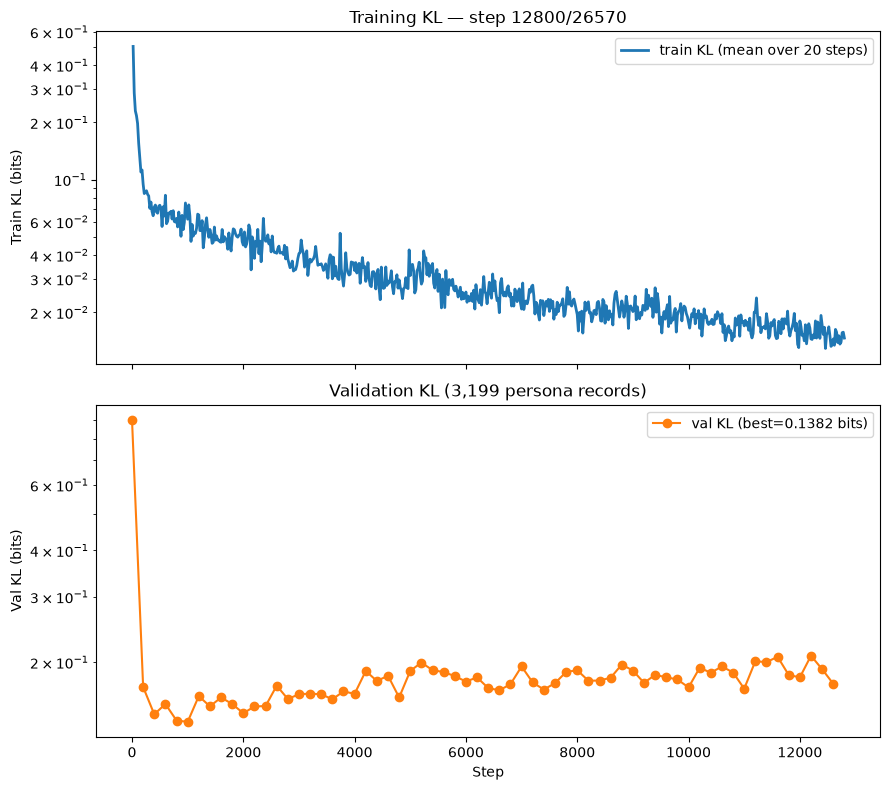

,epoch,step,train_kl,eval_kl,w1,delta_cns
0,0,0,—,0.8990,0.1437,+0.1499
1,1,200,0.0946,0.1715,0.0946,-0.0107
2,1,400,0.0716,0.1448,0.0876,-0.0180
3,1,600,0.0826,0.1543,0.0935,-0.0310
4,1,800,0.0624,0.1393,0.0856,-0.0029
5,1,1000,0.0618,0.1382,0.0895,-0.0159
6,1,1200,0.0651,0.1621,0.0980,-0.0339
7,1,1400,0.0546,0.1521,0.0884,-0.0090
8,1,1600,0.0468,0.1607,0.0947,-0.0005
9,1,1800,0.0497,0.1543,0.0911,-0.0062


[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.


kev-4b-stage1-k1:   0%|          | 0/26570 [00:00<?, ?step/s]

KeyboardInterrupt: 

In [9]:
plotter_s1 = train_stage(
    model,
    train_records=train_records_k1,
    eval_records=eval_records,
    save_dir=stage1_dir,
    init_from=BASE_MODEL,
    epochs=10,
    lr=1e-4,
    batch_size=8,
    val_every=200,
    resume=resume,
)

## 2 attributes training

In [12]:
resume = False
stage2_dir = Path("runs/kev-9b-stage2-k2")


In [13]:

model = None
ckpt = (stage2_dir / "last") if resume else (stage1_dir / "best")
model = load_checkpoint(ckpt, device=device, trainable=True)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/427 [00:00<?, ?it/s]

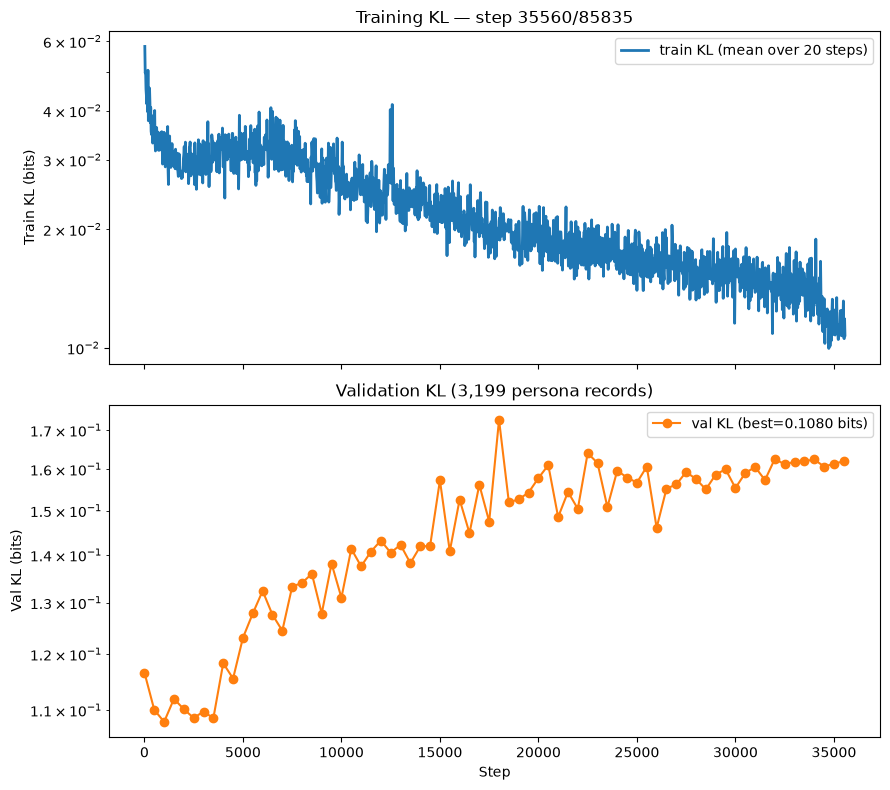

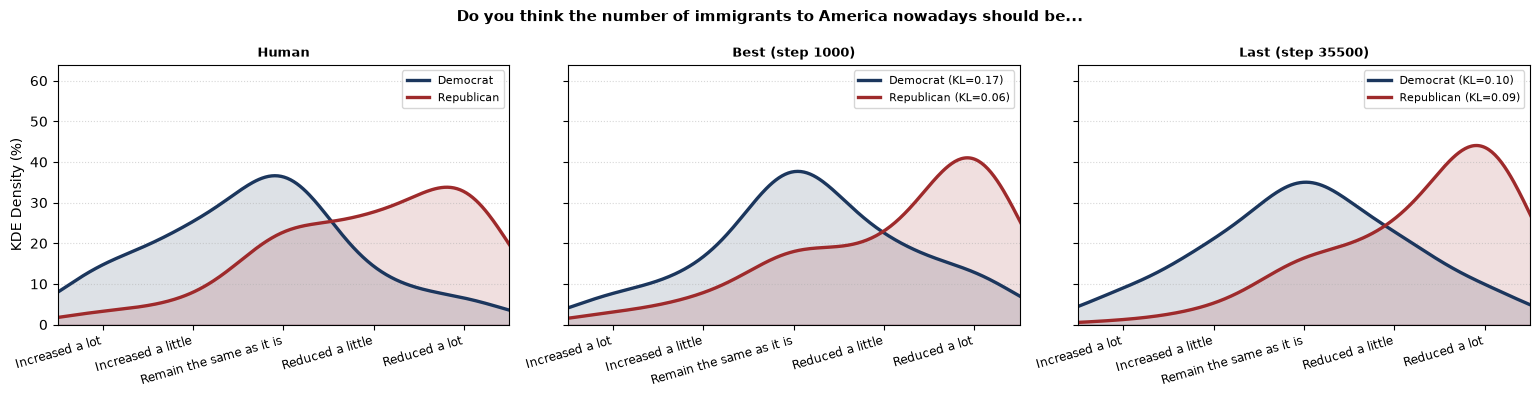

,epoch,step,train_kl,eval_kl,w1,delta_cns
0,0,0,—,0.1166,0.0756,-0.0274
1,1,500,0.0339,0.1100,0.0755,-0.0162
2,1,1000,0.0352,0.1080,0.0750,-0.0146
3,1,1500,0.0289,0.1119,0.0762,-0.0107
4,1,2000,0.0309,0.1102,0.0752,-0.0211
5,1,2500,0.0309,0.1087,0.0748,-0.0030
6,1,3000,0.0295,0.1097,0.0754,-0.0206
7,1,3500,0.0303,0.1086,0.0745,-0.0145
8,1,4000,0.0288,0.1183,0.0796,-0.0265
9,1,4500,0.0313,0.1155,0.0771,-0.0276


kev-9b-stage2-k2:   0%|          | 0/85835 [00:00<?, ?step/s]

KeyboardInterrupt: 

In [14]:
plotter_s2 = train_stage(
    model,
    train_records=train_records_k2,
    eval_records=eval_records,
    save_dir=stage2_dir,
    init_from=ckpt,
    epochs=5,
    lr=5e-5,
    batch_size=8,
    val_every=500,
    resume=resume,
)

## response-level training

In [11]:
resume = False
stage3_dir = Path("runs/kev-9b-stage3-resp")


In [ ]:

model = None
ckpt = (stage3_dir / "last") if resume else (stage2_dir / "best")
model = load_checkpoint(ckpt, device=device, trainable=True)

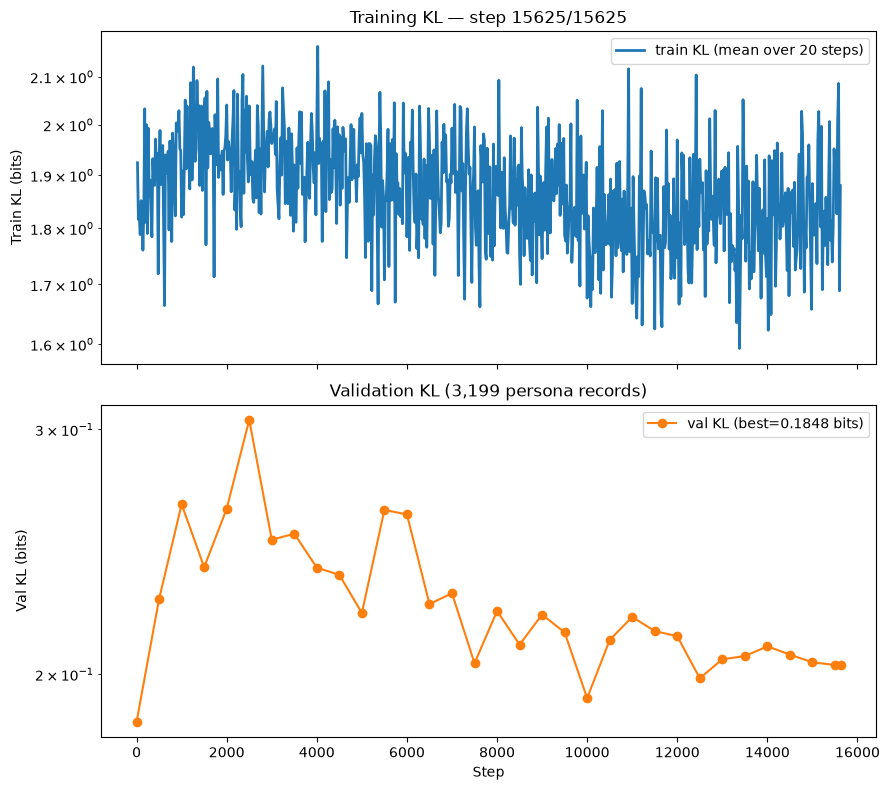

,epoch,step,train_kl,eval_kl,w1,delta_cns
0,0,0,—,0.1848,0.1062,-0.0208
1,1,500,1.9255,0.2266,0.1116,+0.0200
2,1,1000,1.8206,0.2651,0.1246,-0.0120
3,1,1500,2.0370,0.2388,0.1194,-0.0537
4,1,2000,2.0405,0.2631,0.1270,-0.0322
5,1,2500,2.0386,0.3048,0.1338,-0.0027
6,1,3000,1.9620,0.2499,0.1203,-0.0096
7,2,3500,1.9198,0.2524,0.1145,-0.0116
8,2,4000,2.0025,0.2387,0.1196,-0.0287
9,2,4500,1.9795,0.2358,0.1199,-0.0205


kev-0.8b-stage3-resp:   0%|          | 0/15625 [00:00<?, ?step/s]

In [ ]:

plotter_s3 = train_stage(
    model,
    train_records=train_records_resp,
    eval_records=eval_records,
    save_dir=stage3_dir,
    init_from=ckpt,
    epochs=5,
    lr=2e-5,
    batch_size=8,
    val_every=500,
    samples_per_epoch=None,
    resume=resume,
)

## response-level training (from scratch)

In [19]:
resume = False
stage3_scratch_dir = Path("runs/kev-9b-stage3-scratch-resp")


In [20]:
BASE_MODEL = "jaredpalmer/kev-9b"
LORA_RANK = 64
device = "cuda"

model = None
if resume:
    model = load_checkpoint(stage3_scratch_dir / "last", device=device, trainable=True)
else:
    free_gpu()
    model = KevPointerModel.build(BASE_MODEL, device, lora_rank=LORA_RANK, weights_dtype="bf16")
    model.net.head.temperature = 1.0
    model.enable_checkpointing()

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 10 files:   0%|          | 0/10 [00:00<?, ?it/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/427 [00:00<?, ?it/s]

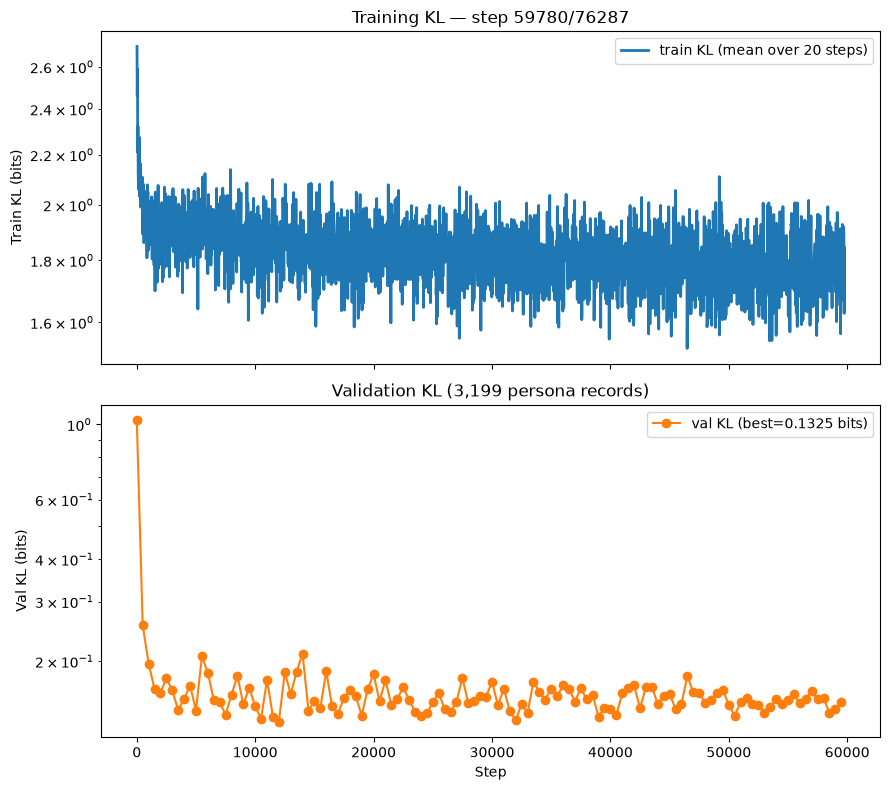

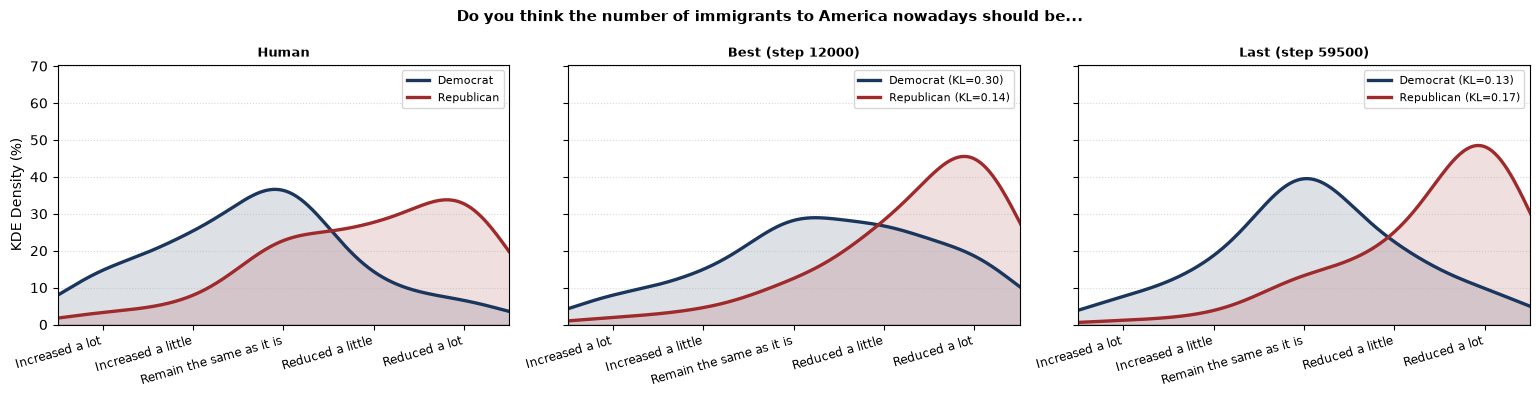

,epoch,step,train_kl,eval_kl,w1,delta_cns
0,0,0,—,1.0314,0.1588,+0.1675
1,1,500,2.0140,0.2554,0.1079,+0.0080
2,1,1000,1.8354,0.1969,0.0959,+0.0143
3,1,1500,1.9866,0.1655,0.0912,+0.0049
4,1,2000,1.9947,0.1615,0.0916,-0.0168
5,1,2500,2.0004,0.1780,0.0937,+0.0175
6,1,3000,2.0495,0.1639,0.0894,-0.0169
7,1,3500,1.8655,0.1433,0.0815,+0.0180
8,1,4000,2.0355,0.1550,0.0890,-0.0450
9,1,4500,1.8092,0.1695,0.0836,+0.0231


kev-9b-stage3-scratch-resp:   0%|          | 0/76287 [00:00<?, ?step/s]

KeyboardInterrupt: 

In [21]:
plotter_s3_scratch = train_stage(
    model,
    train_records=train_records_resp,
    eval_records=eval_records,
    save_dir=stage3_scratch_dir,
    init_from=BASE_MODEL,
    epochs=1,
    lr=2e-5,
    batch_size=8,
    val_every=500,
    samples_per_epoch=None,
    resume=resume,
)

## Mix data training

In [12]:
resume = False
stage4_dir = Path("runs/kev-9b-stage4-mix")


In [ ]:

model = None
ckpt = (stage4_dir / "last") if resume else (stage2_dir / "best")
model = load_checkpoint(ckpt, device=device, trainable=True)

In [13]:
print(len(train_records_resp), len(train_records_k1), len(train_records_k2))
train_combined = train_records_resp + train_records_k1 + train_records_k2


610291 21252 137331


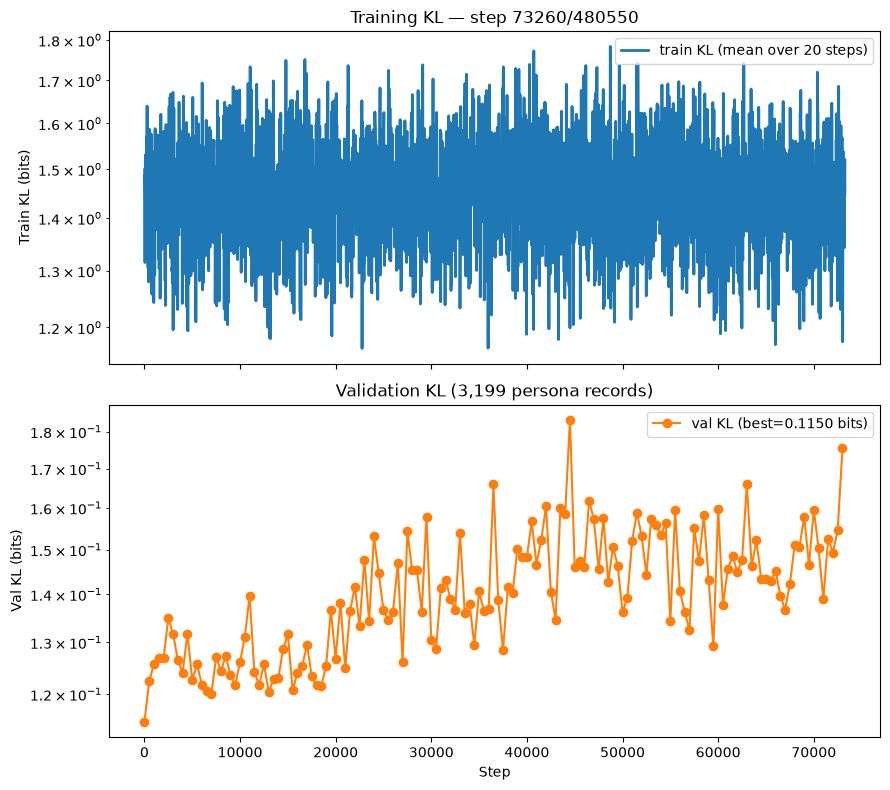

,epoch,step,train_kl,eval_kl,w1,delta_cns
0,0,0,—,0.1150,0.0778,-0.0220
1,1,500,1.3472,0.1224,0.0787,+0.0051
2,1,1000,1.4433,0.1257,0.0795,+0.0097
3,1,1500,1.5161,0.1270,0.0801,+0.0124
4,1,2000,1.4695,0.1269,0.0806,+0.0106
5,1,2500,1.4546,0.1350,0.0816,+0.0219
6,1,3000,1.1961,0.1317,0.0812,+0.0168
7,1,3500,1.5580,0.1264,0.0808,+0.0107
8,1,4000,1.5476,0.1241,0.0804,+0.0062
9,1,4500,1.4998,0.1318,0.0820,+0.0142


kev-4b-stage4-mix:   0%|          | 0/480550 [00:00<?, ?step/s]

KeyboardInterrupt: 

In [14]:
plotter_s4 = train_stage(
    model,
    train_records=train_combined,
    eval_records=eval_records,
    save_dir=stage4_dir,
    init_from=ckpt,
    epochs=5,
    lr=1e-5,
    batch_size=8,
    val_every=500,
    samples_per_epoch=None,
    resume=resume,
)

## Compare training

In [ ]:
model = None
free_gpu()
rows = {"Initial (Zero-shot)": test_summary_init}
for label, ckpt_dir in [
    ("Stage 1 (k=1, 10 ep)", stage1_dir / "best"),
    ("Stage 2 (k=2, 5 ep)", stage2_dir / "best"),
    ("Stage 3 (full, 5 ep)", stage3_dir / "best"),
    ("Stage 4 (mixed, 5 ep)", stage4_dir / "best"),
]:
    if (ckpt_dir / "head.pt").exists():
        m = load_checkpoint(ckpt_dir, device=device, trainable=False)
        summary, test_results_df = evaluate_model(m, test_records, batch_size=64)
        rows[label] = summary
        del m
        free_gpu()

display(pd.DataFrame(rows).T)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/426 [00:00<?, ?it/s]

predict:   0%|          | 0/50 [00:00<?, ?batch/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/426 [00:00<?, ?it/s]

predict:   0%|          | 0/50 [00:00<?, ?batch/s]

,ce,dist_kl,w1,delta_cns
Initial (Zero-shot),2.727184,0.899021,0.143726,0.149909
"Stage 1 (k=1, 10 ep)",1.966220,0.138057,0.089410,-0.015919
"Stage 2 (k=2, 20 ep)",1.943179,0.115017,0.077863,-0.022004


In [14]:
# By-attribute breakdown on the test set
display(test_results_df.groupby("attribute")[["ce", "dist_kl", "w1", "delta_cns"]].mean())

,ce,dist_kl,w1,delta_cns
attribute,,,,
AGE,1.936350,0.111907,0.077441,-0.022503
ATTEND,1.935271,0.112979,0.075683,-0.022458
EDULEVEL,1.938882,0.110757,0.077324,-0.023842
MAINSTAT,1.952821,0.114672,0.078902,-0.024487
MARITAL,1.950274,0.112706,0.076221,-0.017808
PARTY_LR,1.927831,0.128004,0.082638,-0.018462
RELIGGRP,1.928844,0.104999,0.072472,-0.018539
SEX,1.937433,0.104878,0.075951,-0.020772
UNION,1.983422,0.112786,0.076501,-0.020992


# Compare worst eval set errors

Comparing runs/kev-9b-stage2-k2/best vs runs/kev-9b-stage2-k2/last on 3,199 eval_records


,qid,attribute,persona,n,best_kl,last_kl,question
137,2015:v58,PARTY_LR,Political ideology=Conservative,180,0.3001,1.1471,To what extent do you agree or disagree with t...
148,2015:v58,US_PRTY,Political party=Republican,180,0.3259,1.1447,To what extent do you agree or disagree with t...
164,2015:v74,MARITAL,Marital status=Married,107,0.7668,0.9263,To what extent do you agree or disagree with t...
129,2015:v58,RELIGGRP,Religion=Catholic,215,0.4069,0.9224,To what extent do you agree or disagree with t...
152,2015:v58,US_REG,Region=Pacific,124,0.4739,0.9000,To what extent do you agree or disagree with t...
125,2015:v58,AGE,Age=30-49,403,0.3105,0.8657,To what extent do you agree or disagree with t...
134,2015:v58,ATTEND,Attendance of religious services=Several times...,120,0.4669,0.8622,To what extent do you agree or disagree with t...
142,2015:v58,MARITAL,Marital status=Married,413,0.3668,0.8480,To what extent do you agree or disagree with t...
157,2015:v74,SEX,Sex=Male,130,0.5728,0.8427,To what extent do you agree or disagree with t...
752,2017:v30,US_ETHN1,Ancestry=England and Wales,110,0.5356,0.8055,Please say who or where you would turn to firs...


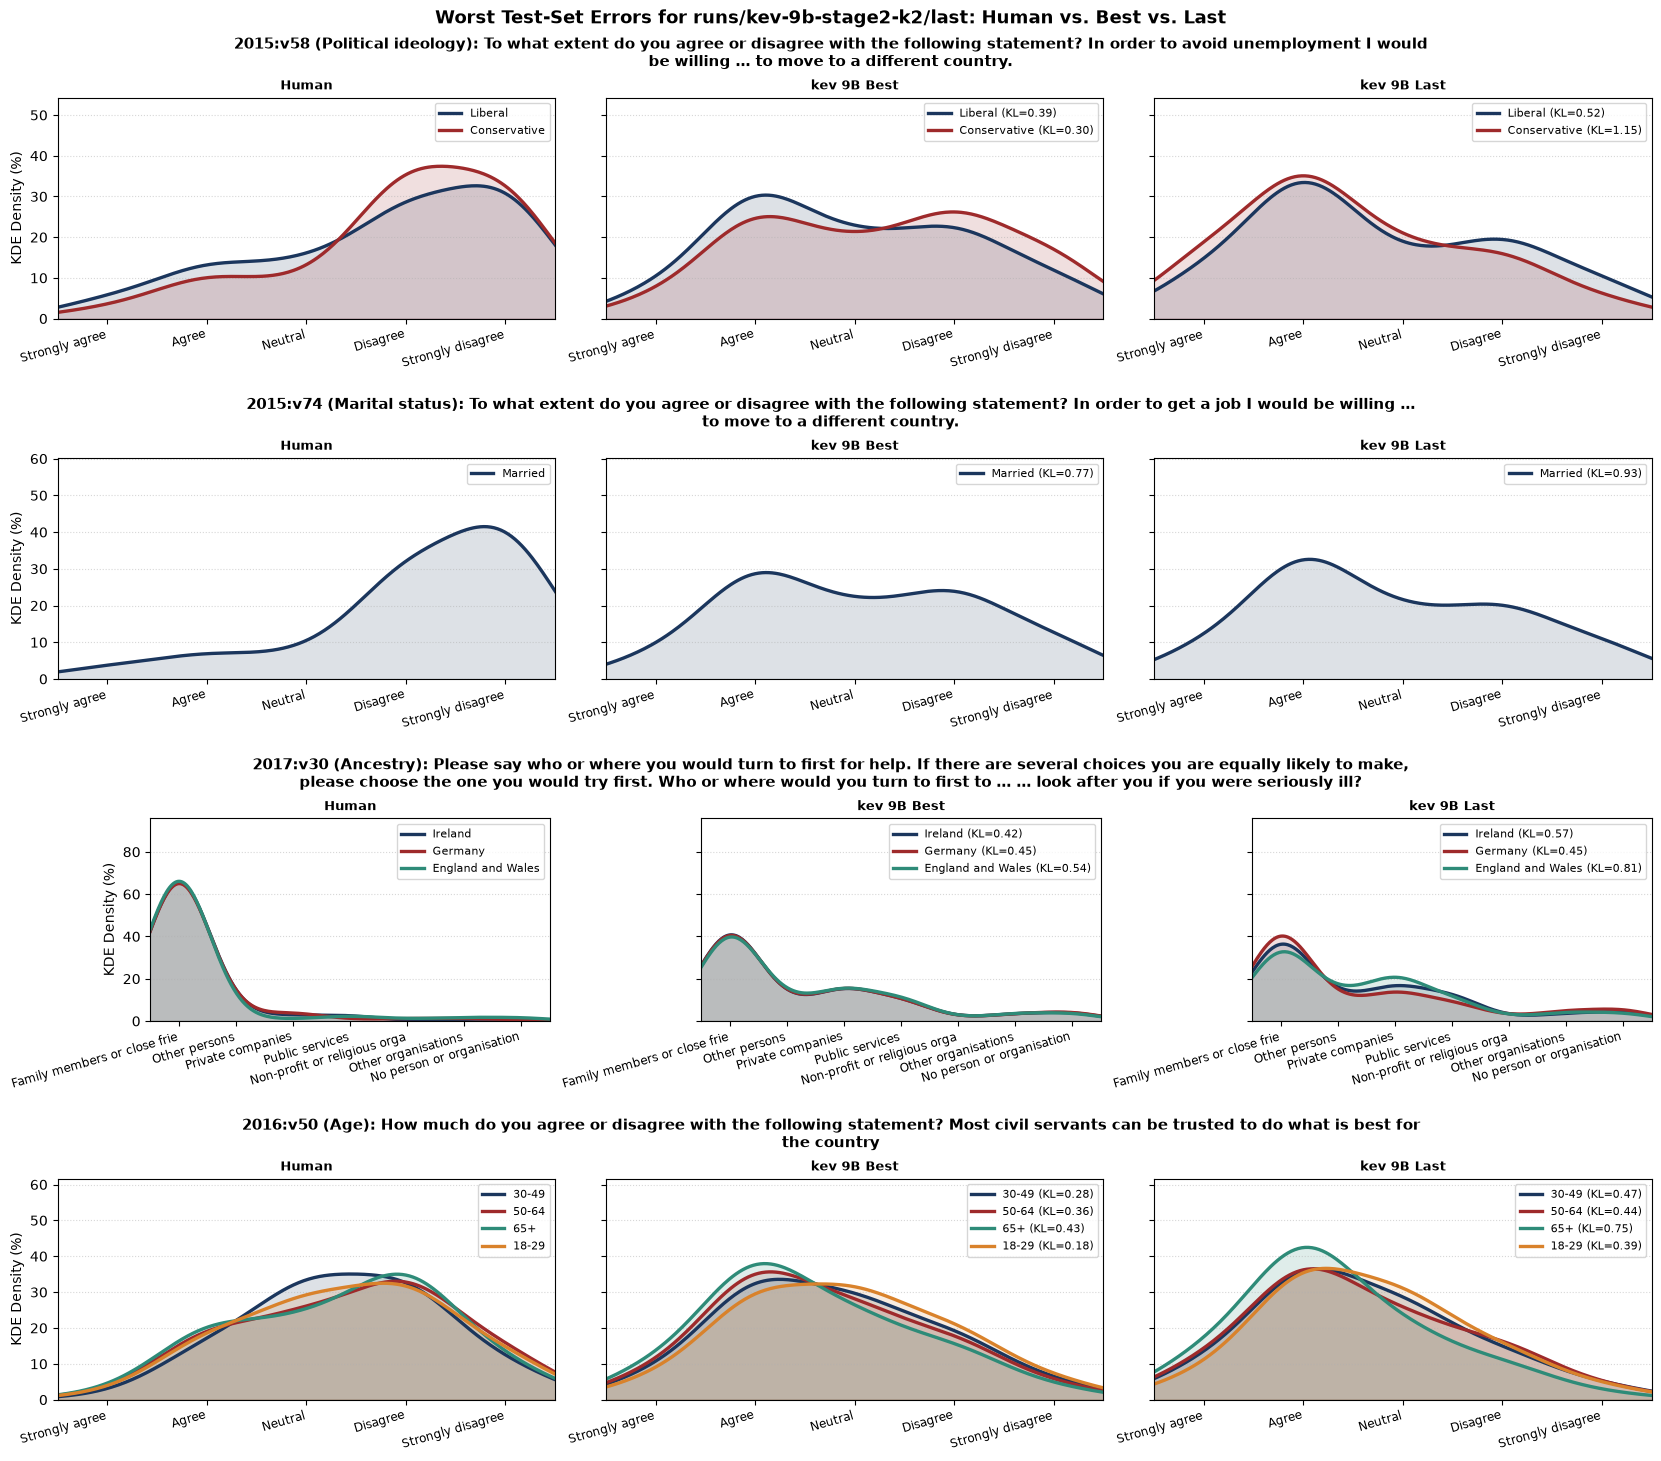

In [22]:
import textwrap

target_stage_dir = stage2_dir if (stage2_dir / "last" / "head.pt").exists() else stage1_dir
best_ckpt = target_stage_dir / "best"
last_ckpt = target_stage_dir / "last"
print(f"Comparing {best_ckpt} vs {last_ckpt} on {len(eval_records):,} eval_records")

if "best_preds" not in globals() or "last_preds" not in globals():
    if "model" in globals():
        del model
    free_gpu()

    m_best = load_checkpoint(best_ckpt, device=device, trainable=False)
    best_preds = predict_probs(m_best, eval_records, batch_size=64)
    del m_best
    free_gpu()

    m_last = load_checkpoint(last_ckpt, device=device, trainable=False)
    last_preds = predict_probs(m_last, eval_records, batch_size=64)
    del m_last
    free_gpu()

best_res_df = evaluate_records(eval_records, best_preds)
last_res_df = evaluate_records(eval_records, last_preds)

err_df = last_res_df[["qid", "type", "attribute", "persona", "n", "dist_kl", "w1"]].rename(
    columns={"dist_kl": "last_kl", "w1": "last_w1"}
).copy()
err_df["best_kl"] = best_res_df["dist_kl"].values
err_df["best_w1"] = best_res_df["w1"].values
err_df["question"] = [r["question"] for r in eval_records]

# Display top 10 worst individual (qid, persona) test records for the last model
display(err_df.sort_values("last_kl", ascending=False)[["qid", "attribute", "persona", "n", "best_kl", "last_kl", "question"]].head(10).round(4))

# Pick the top 4 distinct questions ranked by worst individual last_kl (matching the table above)
worst4_qa = (
    err_df.sort_values("last_kl", ascending=False)
    .drop_duplicates(subset=["qid"], keep="first")[["qid", "attribute", "last_kl"]]
    .head(4)
    .reset_index(drop=True)
)

fig = plt.figure(figsize=(16.5, 14.5), constrained_layout=True)
subfigs = fig.subfigures(4, 1, hspace=0.05)

for row_idx, (subfig, qa_row) in enumerate(zip(subfigs, worst4_qa.to_dict("records"))):
    qid = qa_row["qid"]
    attr_code = qa_row["attribute"]
    idxs = [idx for idx, r in enumerate(eval_records) if r["qid"] == qid and r["attribute"] == attr_code]
    # If an attribute has many levels, keep the 4 levels with highest last_kl for visual clarity
    if len(idxs) > 4:
        idxs = sorted(idxs, key=lambda idx: err_df.loc[idx, "last_kl"], reverse=True)[:4]

    first_rec = eval_records[idxs[0]]
    opts = first_rec["option_texts"]
    short_opts = [o.replace("Neither agree nor disagree", "Neutral").replace("Neither willing nor unwilling", "Neutral")[:28] for o in opts]
    x = np.arange(len(opts), dtype=float)
    x_grid = np.linspace(-0.6, len(opts) - 0.4, 300)

    wrapped_q = textwrap.fill(f"{qid} ({PERSONA_NAMES[attr_code]}): {first_rec['question']}", width=140)
    subfig.suptitle(wrapped_q, fontsize=10.5, fontweight="bold")
    axes_row = subfig.subplots(1, 3, sharey=True)

    panel_sources = [
        ("Human", [eval_records[idx]["human_dist"] for idx in idxs]),
        ("kev 9B Best", [best_preds[idx] for idx in idxs]),
        ("kev 9B Last", [last_preds[idx] for idx in idxs]),
    ]

    top_y = 0.0
    for col_idx, (ax, (panel_name, dists)) in enumerate(zip(axes_row, panel_sources)):
        for i, (idx, dist) in enumerate(zip(idxs, dists)):
            rec = eval_records[idx]
            lvl = rec["personas"][attr_code]
            kde_vals = discrete_kde_curve(dist, x_grid)
            top_y = max(top_y, float(kde_vals.max()))

            if panel_name == "Human":
                lvl_label = f"{lvl}"
            else:
                lvl_kl = evaluate_pair(rec["human_dist"], dist, rec["type"])["dist_kl"]
                lvl_label = f"{lvl} (KL={lvl_kl:.2f})"

            color = LANCET_PALETTE[i % len(LANCET_PALETTE)]
            ax.fill_between(x_grid, kde_vals, color=color, alpha=0.15)
            ax.plot(x_grid, kde_vals, color=color, linewidth=2.4, linestyle="-", label=lvl_label)

        ax.set_xlim(-0.5, len(opts) - 0.5)
        ax.set_xticks(x)
        ax.set_xticklabels(short_opts, rotation=16, ha="right", fontsize=8.5)
        ax.set_title(panel_name, fontsize=9.5, fontweight="bold")
        ax.grid(axis="y", linestyle=":", alpha=0.5)
        ax.legend(frameon=True, fontsize=8, loc="upper right")
        if col_idx == 0:
            ax.set_ylabel("KDE Density (%)")

    for ax in axes_row:
        ax.set_ylim(0, top_y * 1.45)

fig.suptitle(f"Worst Test-Set Errors for {last_ckpt}: Human vs. Best vs. Last", fontsize=13, fontweight="bold")
plt.show()